# OpenFold Colab

Runs a simplified version of [OpenFold](https://github.com/aqlaboratory/openfold) on a target sequence. Adapted from DeepMind's [official AlphaFold Colab](https://colab.research.google.com/github/deepmind/alphafold/blob/main/notebooks/AlphaFold.ipynb).

**Differences to AlphaFold v2.0**

OpenFold is a trainable PyTorch reimplementation of AlphaFold 2. For the purposes of inference, it is practically identical to the original ("practically" because ensembling is excluded from OpenFold (recycling is enabled, however)).

In this notebook, OpenFold is run with your choice of our original OpenFold parameters or DeepMind's publicly released parameters for AlphaFold 2.

**Note**

Like DeepMind's official Colab, this notebook uses **no templates (homologous structures)** and a selected portion of the full [BFD database](https://bfd.mmseqs.com/).

**Citing this work**

Any publication that discloses findings arising from using this notebook should [cite](https://github.com/deepmind/alphafold/#citing-this-work) DeepMind's [AlphaFold paper](https://doi.org/10.1038/s41586-021-03819-2).

**Licenses**

This Colab supports inference with the [AlphaFold model parameters](https://github.com/deepmind/alphafold/#model-parameters-license), made available under the Creative Commons Attribution 4.0 International ([CC BY 4.0](https://creativecommons.org/licenses/by/4.0/legalcode)) license. The Colab itself is provided under the [Apache 2.0 license](https://www.apache.org/licenses/LICENSE-2.0). See the full license statement below.

**More information**

You can find more information about how AlphaFold/OpenFold works in DeepMind's two Nature papers:

*   [AlphaFold methods paper](https://www.nature.com/articles/s41586-021-03819-2)
*   [AlphaFold predictions of the human proteome paper](https://www.nature.com/articles/s41586-021-03828-1)

FAQ on how to interpret AlphaFold/OpenFold predictions are [here](https://alphafold.ebi.ac.uk/faq).

In [1]:
#@markdown ### Enter the amino acid sequence to fold ⬇️
#@markdown For multiple sequences, separate sequences with a colon `:`
input_sequence = 'MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKSRSSSLTLPSSRDPQPLRIQSCYLGDHISDGAWDPEGEGMRGGSRALAAVREATQ'  #@param {type:"string"}

#@markdown ### Configure the model ⬇️

weight_set = 'OpenFold' #@param ["OpenFold", "AlphaFold"]
model_mode = 'monomer' #@param ["monomer", "multimer"]
relax_prediction = True #@param {type:"boolean"}


# Remove all whitespaces, tabs and end lines; upper-case
input_sequence = input_sequence.translate(str.maketrans('', '', ' \n\t')).upper()
aatypes = set('ACDEFGHIKLMNPQRSTVWY')  # 20 standard aatypes
allowed_chars = aatypes.union({':'})
if not set(input_sequence).issubset(allowed_chars):
  raise Exception(f'Input sequence contains non-amino acid letters: {set(input_sequence) - allowed_chars}. OpenFold only supports 20 standard amino acids as inputs.')

if ':' in input_sequence and weight_set != 'AlphaFold':
  raise ValueError('Input sequence is a multimer, must select Alphafold weight set')

import enum
@enum.unique
class ModelType(enum.Enum):
  MONOMER = 0
  MULTIMER = 1

model_type_dict = {
    'monomer': ModelType.MONOMER,
    'multimer': ModelType.MULTIMER,
}

model_type = model_type_dict[model_mode]
print(f'Length of input sequence : {len(input_sequence.replace(":", ""))}')
#@markdown After making your selections, execute this cell by pressing the
#@markdown *Play* button on the left.

Length of input sequence : 100


In [2]:
#@title Install third-party software (repaired)
# Install into the notebook kernel's Python. Do not replace /usr/local with Miniforge.
import os
import sys
import site
import shutil
import subprocess
import importlib
import hashlib
from pathlib import Path
from urllib.request import urlopen
from IPython.utils import io

python_version = f"{sys.version_info.major}.{sys.version_info.minor}"
print("Kernel:", sys.version, "\nExecutable:", sys.executable, flush=True)

pip_executable = shutil.which("pip") or shutil.which("pip3")
if pip_executable is None:
    raise RuntimeError("pip is unavailable. Start this notebook in a fresh Colab runtime.")

# --python makes pip use the kernel interpreter even when pip belongs to another
# interpreter. Explicitly forward subprocess output to Colab and save the full log.
from collections import deque
install_log_path = Path("/content/openfold_install.log")
install_log_path.write_text("")

def run_logged(command, cwd=None):
    tail = deque(maxlen=60)
    with install_log_path.open("a") as log:
        log.write("\nCOMMAND: " + repr(command) + "\n")
        process = subprocess.Popen(
            command, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1,
        )
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            tail.append(line)
        return_code = process.wait()
    if return_code:
        raise RuntimeError(
            f"Command failed ({return_code}). Log: {install_log_path}\n"
            + "".join(tail)
        )

def pip_install(*requirements, extra=()):
    run_logged(
        [pip_executable, "--python", sys.executable, "install",
         "--break-system-packages", *extra, *requirements],
    )

# System tools used by the original notebook's MSA search.
subprocess.run(["apt-get", "update", "-qq"], check=True)
subprocess.run(
    ["apt-get", "install", "-y", "git", "build-essential", "hmmer", "kalign", "hhsuite"],
    check=True,
)

# Use a supported Biopython build for the active Python, rather than forcing 1.83
# into Python 3.13. Keep the existing torch installation if it is already present.
pip_install(
    "setuptools<81", "wheel", "ninja", "torch", "ml-collections", "py3Dmol",
    "modelcif", "dm-tree", "biopython>=1.84", "openmm", "pdbfixer",
)
for package_dir in site.getsitepackages():
    if package_dir not in sys.path:
        site.addsitedir(package_dir)
importlib.invalidate_caches()

# Check CUDA in a fresh process so that an already imported torch cannot hide
# a different installation used by pip during the build.
subprocess.run([
    sys.executable, "-c",
    "import torch; from torch.utils.cpp_extension import CUDA_HOME; "
    "print('Build Python torch:', torch.__version__, 'CUDA:', torch.version.cuda, "
    "'CUDA_HOME:', CUDA_HOME, flush=True); "
    "assert torch.cuda.is_available(), 'Select a GPU runtime in Colab'; "
    "assert CUDA_HOME is not None, 'CUDA compiler toolkit not found in this runtime'"
], check=True)

# Same OpenFold revision as in the uploaded notebook.
os.environ.setdefault("MAX_JOBS", "2")
commit = "1ffd197489aa5f35a5fbce1f00d7dd49bce1bd2f"
# The uploaded build log shows that torch requires C++20 while the pinned
# OpenFold setup.py explicitly passes -std=c++17 to nvcc. Patch that flag only.
build_dir = Path("/content/openfold_build_cxx20")
if not (build_dir / ".git").is_dir():
    run_logged([
        "git", "clone", "--no-checkout",
        "https://github.com/aqlaboratory/openfold.git", str(build_dir),
    ])
run_logged(["git", "-C", str(build_dir), "checkout", "--detach", commit])
setup_path = build_dir / "setup.py"
setup_source = setup_path.read_text()
if "-std=c++17" in setup_source:
    setup_source = setup_source.replace("-std=c++17", "-std=c++20")
    setup_path.write_text(setup_source)
elif "-std=c++20" not in setup_source:
    raise RuntimeError("Unexpected setup.py: neither C++17 nor C++20 flag found.")
print("CUDA build flag: -std=c++20", flush=True)
run_logged(["git", "-C", str(build_dir), "diff", "--", "setup.py"])
pip_install(
    str(build_dir),
    extra=("--no-build-isolation", "--no-deps", "-v"),
)

# Remove the empty namespace package created by the previous failed installation.
for name in list(sys.modules):
    if name == "openfold" or name.startswith("openfold."):
        del sys.modules[name]
importlib.invalidate_caches()
import openfold
from openfold import config
import py3Dmol

# ColabFold keeps an exact copy of the original OpenStructure resource.
# Verify the downloaded bytes before putting the resource into the package.
resource_url = (
    "https://raw.githubusercontent.com/sokrypton/ColabFold/main/"
    "colabfold/openstructure/stereo_chemical_props.txt"
)
with urlopen(resource_url, timeout=60) as response:
    resource_data = response.read()
expected_sha256 = "24510899eeb49167cffedec8fa45363a4d08279c0c637a403b452f7d0ac09451"
if hashlib.sha256(resource_data).hexdigest() != expected_sha256:
    raise RuntimeError("Unexpected stereo_chemical_props.txt checksum; installation stopped.")
resource_path = Path(openfold.__file__).parent / "resources" / "stereo_chemical_props.txt"
resource_path.parent.mkdir(parents=True, exist_ok=True)
resource_path.write_bytes(resource_data)
Path("/content/stereo_chemical_props.txt").write_bytes(resource_data)

ramdisk = Path("/tmp/ramdisk")
ramdisk.mkdir(parents=True, exist_ok=True)
if not os.path.ismount(ramdisk):
    result = subprocess.run(
        ["mount", "-t", "tmpfs", "-o", "size=9G", "ramdisk", str(ramdisk)],
        check=False,
    )
    if result.returncode:
        print("RAM disk unavailable; MSA search will use the ordinary temporary directory.")

print("OpenFold config:", config.__file__)
print("py3Dmol:", py3Dmol.__file__)
print("Resource:", resource_path)
print("Installation finished. Continue with Download model weights.")


Kernel: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] 
Executable: /usr/bin/python3
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 665.9/665.9 kB 7.5 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 21.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.4/14.4 MB 62.2 MB/s  0:00:00
  Created wheel for pdbfixer: filename=pdbfixer-1.12.0-py3-none-any.whl size=681766 sha256=9f71370358194f54ddebeddc5d9c98af1f901ac73253fc6630898eb35dbf7fe3
  Stored in directory: /root/.cache/pip/wheels/a4/56/e2/10e90689958679b4973f87db25f7a9c8a493b08b0e0b6abf26
Successfully built pdbfixer

Cloning into '/content/openfold_build_cxx20'...
HEAD is now 

In [ ]:
import sys
import shutil
import subprocess
from collections import deque

commit = "1ffd197489aa5f35a5fbce1f00d7dd49bce1bd2f"
log_path = "/content/openfold_install.log"

command = [
    shutil.which("pip"),
    "--python", sys.executable,
    "install",
    "--break-system-packages",
    "--no-build-isolation",
    "--no-deps",
    "-v",
    f"git+https://github.com/aqlaboratory/openfold.git@{commit}",
]

tail = deque(maxlen=80)

with open(log_path, "w") as log:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        tail.append(line)

    return_code = process.wait()

print("\nКод завершения:", return_code)
print("Полный лог:", log_path)

if return_code:
    print("\nПоследние 80 строк:\n" + "".join(tail))

Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
  Cloning https://github.com/aqlaboratory/openfold.git (to revision 1ffd197489aa5f35a5fbce1f00d7dd49bce1bd2f) to /tmp/pip-req-build-eufpquki
  Running command git version
  git version 2.43.0
  Running command git clone --filter=blob:none https://github.com/aqlaboratory/openfold.git /tmp/pip-req-build-eufpquki
  Cloning into '/tmp/pip-req-build-eufpquki'...
  Updating files:   0% (2/235)
  Updating files:   1% (3/235)
  Updating files:   2% (5/235)
  Updating files:   3% (8/235)
  Updating files:   4% (10/235)
  Updating files:   5% (12/235)
  Updating files:   6% (15/235)
  Updating files:   7% (17/235)
  Updating files:   8% (19/235)
  Updating files:   9% (22/235)
  Updating files:  10% (24/235)
  Updating files:  11% (26/235)
  Updating files:  12% (29/235)
  Updating files:  13% (31/235)
  Updating files:  14% (33/235)
  Updating files:  15% (36/235)
  Updating files:  16% (38/235)
  Updating files:  1

In [3]:
#@title Download model weights
#@markdown Please execute this cell by pressing the *Play* button on
#@markdown the left.

# Define constants
GIT_REPO='https://github.com/aqlaboratory/openfold'
ALPHAFOLD_PARAM_SOURCE_URL = 'https://storage.googleapis.com/alphafold/alphafold_params_2022-12-06.tar'
OPENFOLD_PARAMS_DIR = './openfold/openfold/resources/openfold_params'
ALPHAFOLD_PARAMS_DIR = './openfold/openfold/resources/params'
ALPHAFOLD_PARAMS_PATH = os.path.join(
  ALPHAFOLD_PARAMS_DIR, os.path.basename(ALPHAFOLD_PARAM_SOURCE_URL)
)

if(weight_set == 'AlphaFold'):
  %shell mkdir --parents "{ALPHAFOLD_PARAMS_DIR}"
  %shell wget -O {ALPHAFOLD_PARAMS_PATH} {ALPHAFOLD_PARAM_SOURCE_URL}
  %shell tar --extract --verbose --file="{ALPHAFOLD_PARAMS_PATH}" \
    --directory="{ALPHAFOLD_PARAMS_DIR}" --preserve-permissions
  %shell rm "{ALPHAFOLD_PARAMS_PATH}"
elif(weight_set == 'OpenFold'):
  # Install AWS CLI
  %shell curl "https://awscli.amazonaws.com/awscli-exe-linux-x86_64.zip" -o "awscliv2.zip"
  %shell unzip -qq awscliv2.zip
  %shell sudo ./aws/install
  %shell rm awscliv2.zip
  %shell rm -rf ./aws
  %shell mkdir --parents "{OPENFOLD_PARAMS_DIR}"

  %shell aws s3 cp \
    --no-sign-request \
    --region us-east-1 \
    s3://openfold/openfold_params "{OPENFOLD_PARAMS_DIR}" \
    --recursive
else:
  raise ValueError("Invalid weight set")


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 72.7M  100 72.7M    0     0   174M      0 --:--:-- --:--:-- --:--:--  174M
You can now run: /usr/local/bin/aws --version
Tip: run 'aws configure agent-toolkit' to set up AWS skills and the AWS MCP server for your AI coding agent(s).
download: s3://openfold/openfold_params/LICENSE to openfold/openfold/resources/openfold_params/LICENSE
download: s3://openfold/openfold_params/README.txt to openfold/openfold/resources/openfold_params/README.txt
download: s3://openfold/openfold_params/finetuning_2.pt to openfold/openfold/resources/openfold_params/finetuning_2.pt
download: s3://openfold/openfold_params/finetuning_3.pt to openfold/openfold/resources/openfold_params/finetuning_3.pt
download: s3://openfold/openfold_params/finetuning_4.pt to openfold/openfold/resources/openfold_params/finetuning_4.pt
download: s3://openfold/openfold_par

In [4]:
#@title Import Python packages
#@markdown Please execute this cell by pressing the *Play* button on
#@markdown the left.

import unittest.mock
import sys
from typing import Dict, Sequence

sys.path.insert(0, f'/usr/local/lib/python{python_version}/dist-packages/')
sys.path.insert(0, f'/usr/local/lib/python{python_version}/site-packages/')

# Allows us to skip installing these packages
unnecessary_modules = [
  "dllogger",
  "pytorch_lightning",
  "pytorch_lightning.utilities",
  "pytorch_lightning.callbacks.early_stopping",
  "pytorch_lightning.utilities.seed",
]
for unnecessary_module in unnecessary_modules:
  sys.modules[unnecessary_module] = unittest.mock.MagicMock()

import os

from urllib import request
from concurrent import futures
from google.colab import files
import json
from matplotlib import gridspec
import matplotlib.pyplot as plt
import numpy as np
import py3Dmol
import torch
import shutil
import tqdm
import tqdm.notebook

TQDM_BAR_FORMAT = '{l_bar}{bar}| {n_fmt}/{total_fmt} [elapsed: {elapsed} remaining: {remaining}]'

# Prevent shell magic being broken by openmm, prevent this cryptic error:
# "NotImplementedError: A UTF-8 locale is required. Got ANSI_X3.4-1968"
import locale
def getpreferredencoding(do_setlocale = True):
    return "UTF-8"
locale.getpreferredencoding = getpreferredencoding

from openfold import config
from openfold.data import feature_pipeline
from openfold.data import parsers
from openfold.data import data_pipeline
from openfold.data import msa_pairing
from openfold.data import feature_processing_multimer
from openfold.data.tools import jackhmmer
from openfold.model import model
from openfold.np import protein
from openfold.np.relax import relax
from openfold.np.relax.utils import overwrite_b_factors
from openfold.utils.import_weights import import_jax_weights_, import_openfold_weights_
from openfold.utils.tensor_utils import tensor_tree_map

from IPython import display
from ipywidgets import GridspecLayout
from ipywidgets import Output

/usr/local/lib/python3.13/dist-packages/openfold/utils/import_weights.py:31: FutureWarning: functools.partial will be a method descriptor in future Python versions; wrap it in enum.member() if you want to preserve the old behavior
  LinearWeight = partial(  # hack: partial prevents fns from becoming methods
/usr/local/lib/python3.13/dist-packages/openfold/utils/import_weights.py:34: FutureWarning: functools.partial will be a method descriptor in future Python versions; wrap it in enum.member() if you want to preserve the old behavior
  LinearWeightMHA = partial(
/usr/local/lib/python3.13/dist-packages/openfold/utils/import_weights.py:37: FutureWarning: functools.partial will be a method descriptor in future Python versions; wrap it in enum.member() if you want to preserve the old behavior
  LinearMHAOutputWeight = partial(
/usr/local/lib/python3.13/dist-packages/openfold/utils/import_weights.py:40: FutureWarning: functools.partial will be a method descriptor in future Python versions; 

## Making a prediction

Note that the search against databases and the actual prediction can take some time, from minutes to hours, depending on the length of the protein and what type of GPU you are allocated by Colab (see FAQ below).

  0%|          | 0/199 [elapsed: 00:00 remaining: ?]

parsing_results_for_sequence MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKSRSSSLTLPSSRDPQPLRIQSCYLGDHISDGAWDPEGEGMRGGSRALAAVREATQ
53 Sequences Found in smallbfd
1 Sequences Found in mgnify
64 Sequences Found in uniref90

66 Sequences Found in Total



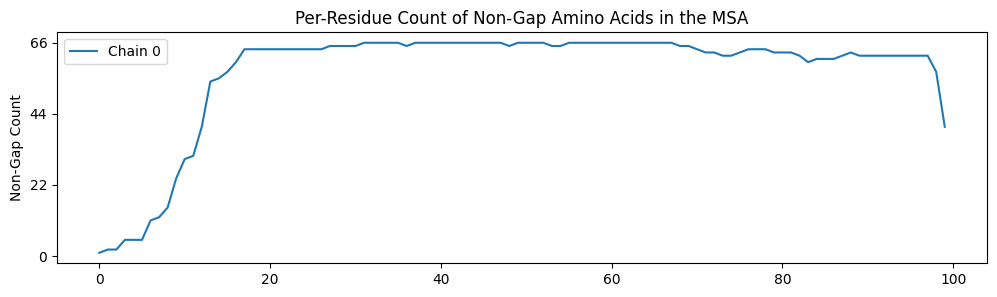

In [5]:
#@title Search against genetic databases

#@markdown Once this cell has been executed, you will see
#@markdown statistics about the multiple sequence alignment
#@markdown (MSA) that will be used by OpenFold. In particular,
#@markdown you’ll see how well each residue is covered by similar
#@markdown sequences in the MSA.

# --- Find the closest source --
test_url_pattern = 'https://storage.googleapis.com/alphafold-colab{:s}/latest/uniref90_2021_03.fasta.1'
ex = futures.ThreadPoolExecutor(3)
def fetch(source):
  request.urlretrieve(test_url_pattern.format(source))
  return source
fs = [ex.submit(fetch, source) for source in ['', '-europe', '-asia']]
source = None
for f in futures.as_completed(fs):
  source = f.result()
  ex.shutdown()
  break

# Run the search against chunks of genetic databases (since the genetic
# databases don't fit in Colab ramdisk).

jackhmmer_binary_path = '/usr/bin/jackhmmer'

# --- Parse multiple sequences, if there are any ---
def split_multiple_sequences(sequence):
  seqs = sequence.split(':')
  sorted_seqs = sorted(seqs, key=lambda s: len(s))

  # TODO: Handle the homomer case when writing fasta sequences
  fasta_path_tuples = []
  for idx, seq in enumerate(set(sorted_seqs)):
    fasta_path = f'target_{idx+1}.fasta'
    with open(fasta_path, 'wt') as f:
      f.write(f'>query\n{seq}\n')
    fasta_path_tuples.append((seq, fasta_path))
  fasta_path_by_seq = dict(fasta_path_tuples)

  return sorted_seqs, fasta_path_by_seq

sequences, fasta_path_by_sequence = split_multiple_sequences(input_sequence)
db_results_by_sequence = {seq: {} for seq in fasta_path_by_sequence.keys()}

DB_ROOT_PATH = f'https://storage.googleapis.com/alphafold-colab{source}/latest/'
db_configs = {}
db_configs['smallbfd'] = {
    'database_path': f'{DB_ROOT_PATH}uniref90_2021_03.fasta',
    'z_value': 65984053,
    'num_jackhmmer_chunks': 17,
}
db_configs['mgnify'] = {
    'database_path': f'{DB_ROOT_PATH}mgy_clusters_2022_05.fasta',
    'z_value': 304820129,
    'num_jackhmmer_chunks': 120,
}
db_configs['uniref90'] = {
     'database_path': f'{DB_ROOT_PATH}uniref90_2022_01.fasta',
     'z_value': 144113457,
     'num_jackhmmer_chunks': 62,
}

# Search UniProt and construct the all_seq features only for heteromers, not homomers.
if model_type == ModelType.MULTIMER and len(set(sequences)) > 1:
  db_configs['uniprot'] = {
       'database_path': f'{DB_ROOT_PATH}uniprot_2021_04.fasta',
       'z_value': 225013025 + 565928,
       'num_jackhmmer_chunks': 101,
       }

total_jackhmmer_chunks = sum([d['num_jackhmmer_chunks'] for d in db_configs.values()])
with tqdm.notebook.tqdm(total=total_jackhmmer_chunks, bar_format=TQDM_BAR_FORMAT) as pbar:
  def jackhmmer_chunk_callback(i):
    pbar.update(n=1)

  for db_name, db_config in db_configs.items():
    pbar.set_description(f'Searching {db_name}')
    jackhmmer_runner = jackhmmer.Jackhmmer(
        binary_path=jackhmmer_binary_path,
        database_path=db_config['database_path'],
        get_tblout=True,
        num_streamed_chunks=db_config['num_jackhmmer_chunks'],
        streaming_callback=jackhmmer_chunk_callback,
        z_value=db_config['z_value'])

    db_results = jackhmmer_runner.query_multiple(fasta_path_by_sequence.values())
    for seq, result in zip(fasta_path_by_sequence.keys(), db_results):
      db_results_by_sequence[seq][db_name] = result


# --- Extract the MSAs and visualize ---
# Extract the MSAs from the Stockholm files.
# NB: deduplication happens later in data_pipeline.make_msa_features.

MAX_HITS_BY_DB = {
    'uniref90': 10000,
    'smallbfd': 5000,
    'mgnify': 501,
    'uniprot': 50000,
}

msas_by_seq_by_db = {seq: {} for seq in sequences}
full_msa_by_seq = {seq: [] for seq in sequences}

for seq, sequence_result in db_results_by_sequence.items():
  print(f'parsing_results_for_sequence {seq}')
  for db_name, db_results in sequence_result.items():
    unsorted_results = []
    for i, result in enumerate(db_results):
      msa_obj = parsers.parse_stockholm(result['sto'])
      e_values_dict = parsers.parse_e_values_from_tblout(result['tbl'])
      target_names = msa_obj.descriptions
      e_values = [e_values_dict[t.split('/')[0]] for t in target_names]
      zipped_results = zip(msa_obj.sequences, msa_obj.deletion_matrix, target_names, e_values)
      if i != 0:
        # Only take query from the first chunk
        zipped_results = [x for x in zipped_results if x[2] != 'query']
      unsorted_results.extend(zipped_results)
    sorted_by_evalue = sorted(unsorted_results, key=lambda x: x[3])
    msas, del_matrix, targets, _ = zip(*sorted_by_evalue)
    db_msas = parsers.Msa(msas, del_matrix, targets)
    if db_msas:
      if db_name in MAX_HITS_BY_DB:
        db_msas.truncate(MAX_HITS_BY_DB[db_name])
      msas_by_seq_by_db[seq][db_name] = db_msas
      full_msa_by_seq[seq].extend(db_msas.sequences)
      msa_size = len(set(db_msas.sequences))
      print(f'{msa_size} Sequences Found in {db_name}')


fig = plt.figure(figsize=(12, 3))
max_num_alignments = 0

for seq_idx, seq in enumerate(set(sequences)):
  full_msas = full_msa_by_seq[seq]
  deduped_full_msa = list(dict.fromkeys(full_msas))
  total_msa_size = len(deduped_full_msa)
  print(f'\n{total_msa_size} Sequences Found in Total\n')

  aa_map = {restype: i for i, restype in enumerate('ABCDEFGHIJKLMNOPQRSTUVWXYZ-')}
  msa_arr = np.array([[aa_map[aa] for aa in seq] for seq in deduped_full_msa])
  num_alignments, num_res = msa_arr.shape
  plt.plot(np.sum(msa_arr != aa_map['-'], axis=0), label=f'Chain {seq_idx}')
  max_num_alignments = max(num_alignments, max_num_alignments)


plt.title('Per-Residue Count of Non-Gap Amino Acids in the MSA')
plt.ylabel('Non-Gap Count')
plt.yticks(range(0, max_num_alignments + 1, max(1, int(max_num_alignments / 3))))
plt.legend()
plt.show()

In [7]:
#@title Run OpenFold and download prediction

#@markdown Once this cell has been executed, a zip-archive with
#@markdown the obtained prediction will be automatically downloaded
#@markdown to your computer.

# Color bands for visualizing plddt
PLDDT_BANDS = [
  (0, 50, '#FF7D45'),
  (50, 70, '#FFDB13'),
  (70, 90, '#65CBF3'),
  (90, 100, '#0053D6')
]

# --- Run the model ---
if model_type == ModelType.MONOMER:
  model_names = [
   'finetuning_3.pt',
   'finetuning_4.pt',
   'finetuning_5.pt',
   'finetuning_ptm_2.pt',
   'finetuning_no_templ_ptm_1.pt'
  ]
elif model_type == ModelType.MULTIMER:
  model_names = [
    'model_1_multimer_v3',
    'model_2_multimer_v3',
    'model_3_multimer_v3',
    'model_4_multimer_v3',
    'model_5_multimer_v3',
  ]

def _placeholder_template_feats(num_templates_, num_res_):
  return {
      'template_aatype': np.zeros((num_templates_, num_res_, 22), dtype=np.int64),
      'template_all_atom_positions': np.zeros((num_templates_, num_res_, 37, 3), dtype=np.float32),
      'template_all_atom_mask': np.zeros((num_templates_, num_res_, 37), dtype=np.float32),
      'template_domain_names': np.zeros((num_templates_,), dtype=np.float32),
      'template_sum_probs': np.zeros((num_templates_, 1), dtype=np.float32),
  }


def make_features(
    sequences: Sequence[str],
    msas_by_seq_by_db: Dict[str, Dict[str, parsers.Msa]],
    model_type: ModelType):
  num_templates = 1 # Placeholder for generating fake template features
  feature_dict = {}

  for idx, seq in enumerate(sequences, start=1):
    _chain_id = f'chain_{idx}'
    num_res = len(seq)

    feats = data_pipeline.make_sequence_features(seq, _chain_id, num_res)
    msas_without_uniprot = [msas_by_seq_by_db[seq][db] for db in db_configs.keys() if db != 'uniprot']
    msa_feats = data_pipeline.make_msa_features(msas_without_uniprot)
    feats.update(msa_feats)
    feats.update(_placeholder_template_feats(num_templates, num_res))

    if model_type == ModelType.MONOMER:
      feature_dict[seq] = feats
    if model_type == ModelType.MULTIMER:
      # Perform extra pair processing steps for heteromers
      if len(set(sequences)) > 1:
        uniprot_msa = msas_by_seq_by_db[seq]['uniprot']
        uniprot_msa_features = data_pipeline.make_msa_features([uniprot_msa])
        valid_feat_names = msa_pairing.MSA_FEATURES + (
                'msa_species_identifiers',
            )
        pair_feats = {
                f'{k}_all_seq': v for k, v in uniprot_msa_features.items()
                if k in valid_feat_names
            }
        feats.update(pair_feats)

      feats = data_pipeline.convert_monomer_features(feats, _chain_id)
      feature_dict[_chain_id] = feats

  if model_type == ModelType.MONOMER:
    np_example = feature_dict[sequences[0]]
  elif model_type == ModelType.MULTIMER:
    all_chain_feats = data_pipeline.add_assembly_features(feature_dict)
    features = feature_processing_multimer.pair_and_merge(all_chain_features=all_chain_feats)
    np_example = data_pipeline.pad_msa(features, 512)

  return np_example


output_dir = 'prediction'
os.makedirs(output_dir, exist_ok=True)

plddts = {}
pae_outputs = {}
weighted_ptms = {}
unrelaxed_proteins = {}

with tqdm.notebook.tqdm(total=len(model_names), bar_format=TQDM_BAR_FORMAT) as pbar:
  for i, model_name in enumerate(model_names, start = 1):
    pbar.set_description(f'Running {model_name}')

    feature_dict = make_features(sequences, msas_by_seq_by_db, model_type)

    if(weight_set == "AlphaFold"):
      if model_type == ModelType.MONOMER:
        config_preset = f"model_{i}"
      elif model_type == ModelType.MULTIMER:
        config_preset = f'model_{i}_multimer_v3'
    else:
      if("_no_templ_" in model_name):
        config_preset = "model_3"
      else:
        config_preset = "model_1"
      if("_ptm_" in model_name):
        config_preset += "_ptm"

    cfg = config.model_config(config_preset)

    # Force the model to only use 3 recycling updates
    cfg.data.common.max_recycling_iters = 3
    cfg.model.recycle_early_stop_tolerance = -1

    openfold_model = model.AlphaFold(cfg)
    openfold_model = openfold_model.eval()
    if(weight_set == "AlphaFold"):
      params_name = os.path.join(
        ALPHAFOLD_PARAMS_DIR, f"params_{config_preset}.npz"
      )
      import_jax_weights_(openfold_model, params_name, version=config_preset)
    elif(weight_set == "OpenFold"):
      params_name = os.path.join(
        OPENFOLD_PARAMS_DIR,
        model_name,
      )
      d = torch.load(params_name, weights_only=False)  # Official OpenFold checkpoints
      import_openfold_weights_(model=openfold_model, state_dict=d)
    else:
      raise ValueError(f"Invalid weight set: {weight_set}")

    openfold_model = openfold_model.cuda()

    pipeline = feature_pipeline.FeaturePipeline(cfg.data)
    processed_feature_dict = pipeline.process_features(
      feature_dict,
      mode='predict',
      is_multimer = (model_type == ModelType.MULTIMER),
    )

    processed_feature_dict = tensor_tree_map(
        lambda t: t.cuda(), processed_feature_dict
    )

    with torch.no_grad():
      prediction_result = openfold_model(processed_feature_dict)

    # Move the batch and output to np for further processing
    processed_feature_dict = tensor_tree_map(
      lambda t: np.array(t[..., -1].cpu()), processed_feature_dict
    )
    prediction_result = tensor_tree_map(
      lambda t: np.array(t.cpu()), prediction_result
    )

    mean_plddt = prediction_result['plddt'].mean()

    if model_type == ModelType.MONOMER:
      if 'predicted_aligned_error' in prediction_result:
        pae_outputs[model_name] = (
            prediction_result['predicted_aligned_error'],
            prediction_result['max_predicted_aligned_error']
        )
      else:
        # Get the pLDDT confidence metrics. Do not put pTM models here as they
        # should never get selected.
        plddts[model_name] = prediction_result['plddt']
    elif model_type == ModelType.MULTIMER:
      # Multimer models are sorted by pTM+ipTM.
      plddts[model_name] = prediction_result['plddt']
      pae_outputs[model_name] = (prediction_result['predicted_aligned_error'],
                                 prediction_result['max_predicted_aligned_error'])

      weighted_ptms[model_name] = prediction_result['weighted_ptm_score']

    # Set the b-factors to the per-residue plddt.
    final_atom_mask = prediction_result['final_atom_mask']
    b_factors = prediction_result['plddt'][:, None] * final_atom_mask
    unrelaxed_protein = protein.from_prediction(
      processed_feature_dict,
      prediction_result,
      remove_leading_feature_dimension=False,
      b_factors=b_factors,
    )
    unrelaxed_proteins[model_name] = unrelaxed_protein

    # Delete unused outputs to save memory.
    del openfold_model
    del processed_feature_dict
    del prediction_result
    pbar.update(n=1)

  # Find the best model according to the mean pLDDT.
  if model_type == ModelType.MONOMER:
    best_model_name = max(plddts.keys(), key=lambda x: plddts[x].mean())
  elif model_type == ModelType.MULTIMER:
    best_model_name = max(weighted_ptms.keys(), key=lambda x: weighted_ptms[x])
  best_pdb = protein.to_pdb(unrelaxed_proteins[best_model_name])

  # --- AMBER relax the best model ---
  if(relax_prediction):
    pbar.set_description(f'AMBER relaxation')
    amber_relaxer = relax.AmberRelaxation(
        max_iterations=0,
        tolerance=2.39,
        stiffness=10.0,
        exclude_residues=[],
        max_outer_iterations=20,
        use_gpu=True,
    )
    relaxed_pdb, _, _ = amber_relaxer.process(
        prot=unrelaxed_proteins[best_model_name]
    )
    best_pdb = relaxed_pdb

  # Write out the prediction
  pred_output_path = os.path.join(output_dir, 'selected_prediction.pdb')
  with open(pred_output_path, 'w') as f:
    f.write(best_pdb)

  pbar.update(n=1)  # Finished AMBER relax.

# Construct multiclass b-factors to indicate confidence bands
# 0=very low, 1=low, 2=confident, 3=very high
banded_b_factors = []
for plddt in plddts[best_model_name]:
  for idx, (min_val, max_val, _) in enumerate(PLDDT_BANDS):
    if plddt >= min_val and plddt <= max_val:
      banded_b_factors.append(idx)
      break
banded_b_factors = np.array(banded_b_factors)[:, None] * final_atom_mask
to_visualize_pdb = overwrite_b_factors(best_pdb, banded_b_factors)

# --- Visualise the prediction & confidence ---
show_sidechains = True
def plot_plddt_legend():
  """Plots the legend for pLDDT."""
  thresh = [
            'Very low (pLDDT < 50)',
            'Low (70 > pLDDT > 50)',
            'Confident (90 > pLDDT > 70)',
            'Very high (pLDDT > 90)']

  colors = [x[2] for x in PLDDT_BANDS]

  plt.figure(figsize=(2, 2))
  for c in colors:
    plt.bar(0, 0, color=c)
  plt.legend(thresh, frameon=False, loc='center', fontsize=20)
  plt.xticks([])
  plt.yticks([])
  ax = plt.gca()
  ax.spines['right'].set_visible(False)
  ax.spines['top'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  plt.title('Model Confidence', fontsize=20, pad=20)
  return plt

# Show the structure coloured by chain if the multimer model has been used.
if model_type == ModelType.MULTIMER:
  multichain_view = py3Dmol.view(width=800, height=600)
  multichain_view.addModelsAsFrames(to_visualize_pdb)
  multichain_style = {'cartoon': {'colorscheme': 'chain'}}
  multichain_view.setStyle({'model': -1}, multichain_style)
  multichain_view.zoomTo()
  multichain_view.show()

# Color the structure by per-residue pLDDT
color_map = {i: bands[2] for i, bands in enumerate(PLDDT_BANDS)}
view = py3Dmol.view(width=800, height=600)
view.addModelsAsFrames(to_visualize_pdb)
style = {'cartoon': {
    'colorscheme': {
        'prop': 'b',
        'map': color_map}
        }}
if show_sidechains:
  style['stick'] = {}
view.setStyle({'model': -1}, style)
view.zoomTo()

grid = GridspecLayout(1, 2)
out = Output()
with out:
  view.show()
grid[0, 0] = out

out = Output()
with out:
  plot_plddt_legend().show()
grid[0, 1] = out

display.display(grid)

# Display pLDDT and predicted aligned error (if output by the model).
if pae_outputs:
  num_plots = 2
else:
  num_plots = 1

plt.figure(figsize=[8 * num_plots, 6])
plt.subplot(1, num_plots, 1)
plt.plot(plddts[best_model_name])
plt.title('Predicted LDDT')
plt.xlabel('Residue')
plt.ylabel('pLDDT')

if num_plots == 2:
  plt.subplot(1, 2, 2)
  pae, max_pae = list(pae_outputs.values())[0]
  plt.imshow(pae, vmin=0., vmax=max_pae, cmap='Greens_r')
  plt.colorbar(fraction=0.046, pad=0.04)

  # Display lines at chain boundaries.
  best_unrelaxed_prot = unrelaxed_proteins[best_model_name]
  total_num_res = best_unrelaxed_prot.residue_index.shape[-1]
  chain_ids = best_unrelaxed_prot.chain_index
  for chain_boundary in np.nonzero(chain_ids[:-1] - chain_ids[1:]):
    if chain_boundary.size:
      plt.plot([0, total_num_res], [chain_boundary, chain_boundary], color='red')
      plt.plot([chain_boundary, chain_boundary], [0, total_num_res], color='red')
  plt.title('Predicted Aligned Error')
  plt.xlabel('Scored residue')
  plt.ylabel('Aligned residue')

# Save pLDDT and predicted aligned error (if it exists)
pae_output_path = os.path.join(output_dir, 'predicted_aligned_error.json')
if pae_outputs:
  # Save predicted aligned error in the same format as the AF EMBL DB
  rounded_errors = np.round(pae.astype(np.float64), decimals=1)
  indices = np.indices((len(rounded_errors), len(rounded_errors))) + 1
  indices_1 = indices[0].flatten().tolist()
  indices_2 = indices[1].flatten().tolist()
  pae_data = json.dumps([{
      'residue1': indices_1,
      'residue2': indices_2,
      'distance': rounded_errors.flatten().tolist(),
      'max_predicted_aligned_error': max_pae.item()
  }],
                        indent=None,
                        separators=(',', ':'))
  with open(pae_output_path, 'w') as f:
    f.write(pae_data)


# --- Download the predictions ---
shutil.make_archive(base_name='prediction', format='zip', root_dir=output_dir)
files.download(f'{output_dir}.zip')

  0%|          | 0/5 [elapsed: 00:00 remaining: ?]

/usr/local/lib/python3.13/dist-packages/openfold/utils/tensor_utils.py:92: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:356.)
  return data[ranges]
/usr/local/lib/python3.13/dist-packages/openfold/data/data_transforms.py:1261: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:356.)
  protein[k] = v[slices]
/usr/lo

There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform called "CUDA"
There is no registered Platform ca

ValueError: Minimization failed after 100 attempts.

In [8]:
from pathlib import Path
import shutil
from google.colab import files

out = Path(output_dir)
out.mkdir(parents=True, exist_ok=True)

# Сначала сохраняем все уже рассчитанные модели.
for name, predicted_protein in unrelaxed_proteins.items():
    path = out / f"{Path(name).stem}_unrelaxed.pdb"
    path.write_text(protein.to_pdb(predicted_protein))

best_unrelaxed = protein.to_pdb(
    unrelaxed_proteins[best_model_name]
)
(out / "selected_prediction_unrelaxed.pdb").write_text(best_unrelaxed)

print("Модели сохранены. Лучшая модель:", best_model_name)
print("Запускаю AMBER-релаксацию на CPU…", flush=True)

try:
    amber_relaxer = relax.AmberRelaxation(
        max_iterations=0,
        tolerance=2.39,
        stiffness=10.0,
        exclude_residues=[],
        max_outer_iterations=20,
        use_gpu=False,
    )

    relaxed_pdb, _, _ = amber_relaxer.process(
        prot=unrelaxed_proteins[best_model_name]
    )

    (out / "selected_prediction_relaxed.pdb").write_text(relaxed_pdb)
    status = "AMBER relaxation completed on CPU."
    print("Релаксация завершена.")

except Exception as error:
    status = f"AMBER relaxation failed: {error}"
    print(status)
    print("Предсказания без релаксации сохранены.")

(out / "relaxation_status.txt").write_text(
    f"Selected model: {best_model_name}\n{status}\n"
)

archive = shutil.make_archive(
    "/content/openfold_prediction",
    "zip",
    root_dir=str(out.resolve()),
)
files.download(archive)

Модели сохранены. Лучшая модель: finetuning_3.pt
Запускаю AMBER-релаксацию на CPU…
Релаксация завершена.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Interpreting the prediction

Please see the [AlphaFold methods paper](https://www.nature.com/articles/s41586-021-03819-2) and the [AlphaFold predictions of the human proteome paper](https://www.nature.com/articles/s41586-021-03828-1), as well as [DeepMind's FAQ](https://alphafold.ebi.ac.uk/faq) on how to interpret AlphaFold/OpenFold predictions. More information about the predictions of the AlphaFold Multimer model can be found in the [Alphafold Multimer paper](https://www.biorxiv.org/content/10.1101/2022.03.11.484043v3.full.pdf).

## FAQ & Troubleshooting


*   How do I get a predicted protein structure for my protein?
    *   Click on the _Connect_ button on the top right to get started.
    *   Paste the amino acid sequence of your protein (without any headers) into the “Enter the amino acid sequence to fold”.
    *   Run all cells in the Colab, either by running them individually (with the play button on the left side) or via _Runtime_ > _Run all._
    *   The predicted protein structure will be downloaded once all cells have been executed. Note: This can take minutes to hours - see below.
*   How long will this take?
    *   Downloading the OpenFold source code can take up to a few minutes.
    *   Downloading and installing the third-party software can take up to a few minutes.
    *   The search against genetic databases can take minutes to hours.
    *   Running OpenFold and generating the prediction can take minutes to hours, depending on the length of your protein and on which GPU-type Colab has assigned you.
*   My Colab no longer seems to be doing anything, what should I do?
    *   Some steps may take minutes to hours to complete.
    *   Sometimes, running the "installation" cells more than once can corrupt the OpenFold installation.
    *   If nothing happens or if you receive an error message, try restarting your Colab runtime via _Runtime_ > _Restart runtime_.
    *   If this doesn’t help, reset your Colab runtime via _Runtime_ > _Factory reset runtime_.
*   How does what's run in this notebook compare to the full versions of Alphafold/Openfold?
    *   This Colab version of OpenFold searches a selected portion of the BFD dataset and currently doesn’t use templates, so its accuracy is reduced in comparison to the full version, which is analogous to what's described in the [AlphaFold paper](https://doi.org/10.1038/s41586-021-03819-2) and [Github repo](https://github.com/deepmind/alphafold/). The full version of OpenFold can be run from our own [GitHub repo](https://github.com/aqlaboratory/openfold).
*   What is a Colab?
    *   See the [Colab FAQ](https://research.google.com/colaboratory/faq.html).
*   I received a warning “Notebook requires high RAM”, what do I do?
    *   The resources allocated to your Colab vary. See the [Colab FAQ](https://research.google.com/colaboratory/faq.html) for more details.
    *   You can execute the Colab nonetheless.
*   I received an error “Colab CPU runtime not supported” or “No GPU/TPU found”, what do I do?
    *   Colab CPU runtime is not supported. Try changing your runtime via _Runtime_ > _Change runtime type_ > _Hardware accelerator_ > _GPU_.
    *   The type of GPU allocated to your Colab varies. See the [Colab FAQ](https://research.google.com/colaboratory/faq.html) for more details.
    *   If you receive “Cannot connect to GPU backend”, you can try again later to see if Colab allocates you a GPU.
    *   [Colab Pro](https://colab.research.google.com/signup) offers priority access to GPUs.
*   Does this tool install anything on my computer?
    *   No, everything happens in the cloud on Google Colab.
    *   At the end of the Colab execution a zip-archive with the obtained prediction will be automatically downloaded to your computer.
*   How should I share feedback and bug reports?
    *   Please share any feedback and bug reports as an [issue](https://github.com/aqlaboratory/openfold/issues) on Github.


# License and Disclaimer

This Colab notebook and other information provided is for theoretical modelling only, caution should be exercised in its use. It is provided ‘as-is’ without any warranty of any kind, whether expressed or implied. Information is not intended to be a substitute for professional medical advice, diagnosis, or treatment, and does not constitute medical or other professional advice.

## AlphaFold/OpenFold Code License

Copyright 2021 AlQuraishi Laboratory

Copyright 2021 DeepMind Technologies Limited.

Licensed under the Apache License, Version 2.0 (the "License"); you may not use this file except in compliance with the License. You may obtain a copy of the License at https://www.apache.org/licenses/LICENSE-2.0.

Unless required by applicable law or agreed to in writing, software distributed under the License is distributed on an "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied. See the License for the specific language governing permissions and limitations under the License.

## Model Parameters License

DeepMind's AlphaFold parameters are made available under the terms of the Creative Commons Attribution 4.0 International (CC BY 4.0) license. You can find details at: https://creativecommons.org/licenses/by/4.0/legalcode


## Third-party software

Use of the third-party software, libraries or code referred to in this notebook may be governed by separate terms and conditions or license provisions. Your use of the third-party software, libraries or code is subject to any such terms and you should check that you can comply with any applicable restrictions or terms and conditions before use.


## Mirrored Databases

The following databases have been mirrored by DeepMind, and are available with reference to the following:
* UniRef90: v2021\_03 (unmodified), by The UniProt Consortium, available under a [Creative Commons Attribution-NoDerivatives 4.0 International License](http://creativecommons.org/licenses/by-nd/4.0/).
* MGnify: v2019\_05 (unmodified), by Mitchell AL et al., available free of all copyright restrictions and made fully and freely available for both non-commercial and commercial use under [CC0 1.0 Universal (CC0 1.0) Public Domain Dedication](https://creativecommons.org/publicdomain/zero/1.0/).
* BFD: (modified), by Steinegger M. and Söding J., modified by DeepMind, available under a [Creative Commons Attribution-ShareAlike 4.0 International License](https://creativecommons.org/licenses/by/4.0/). See the Methods section of the [AlphaFold proteome paper](https://www.nature.com/articles/s41586-021-03828-1) for details.